In [15]:
import openseespy.opensees as ops
import numpy as np
import matplotlib.pyplot as plt 
import math 
import opsvis as opsv 

In [16]:
E=200*10**9
A=0.03
I=300*10**-6
nbay=3
hbay=5
wbay=10


In [17]:

ops.wipe()
ops.model('basic','-ndm',2,'-ndf',3)

#base node 
for i in range(nbay+1):
    index=i+1
    xcoord=i*wbay
    nodetag=2*index-1
    if (i==3):
        ycoord=5
    else:
        ycoord=0
    ops.node(nodetag,xcoord,ycoord)
    print(f'base node with tag{nodetag} defined')

#eaves node 

for i in range(nbay+1):
    index=i+1
    xcoord=i*wbay
    nodetag=2*index
    ycoord=10
    ops.node(nodetag,xcoord,ycoord)
    print(f'eaves node with tag{nodetag} defined')


base node with tag1 defined
base node with tag3 defined
base node with tag5 defined
base node with tag7 defined
eaves node with tag2 defined
eaves node with tag4 defined
eaves node with tag6 defined
eaves node with tag8 defined


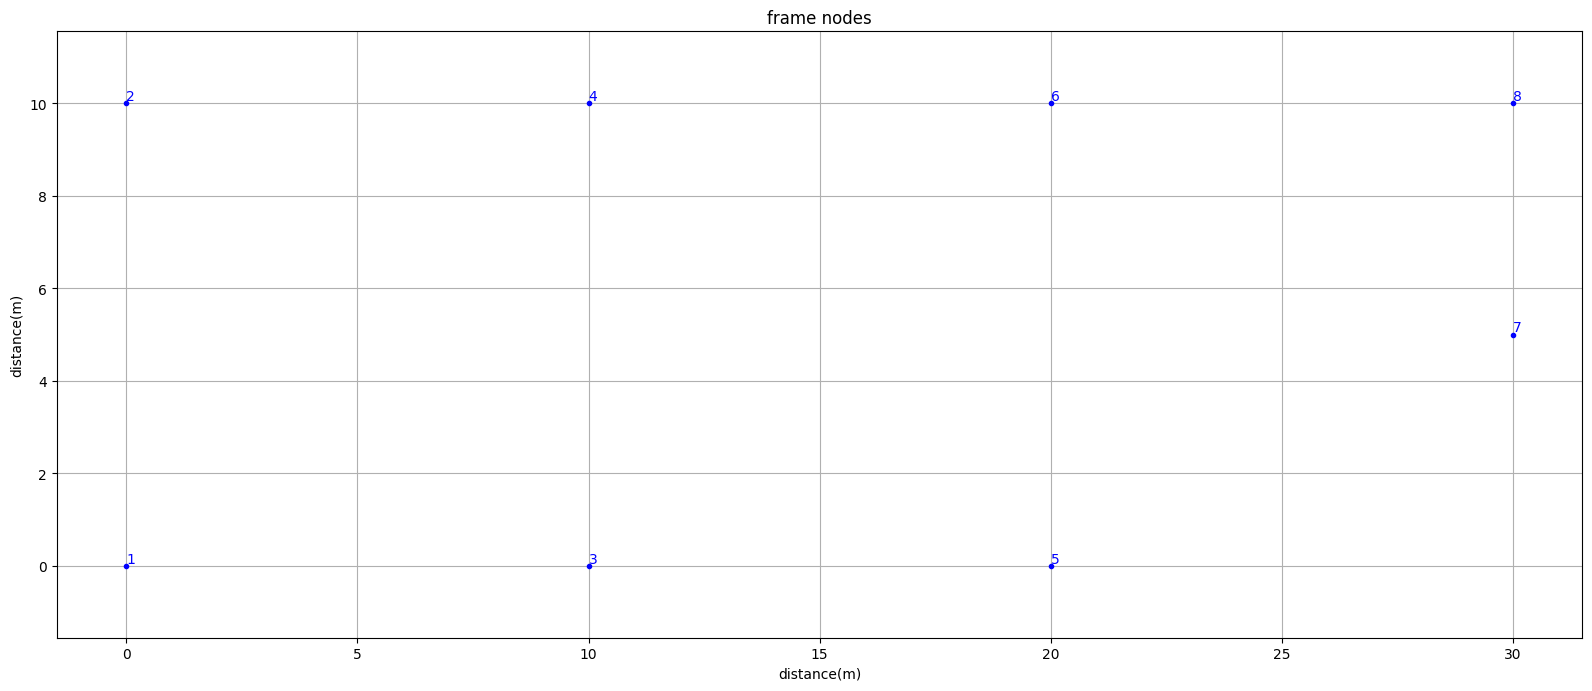

In [18]:
def plotstructure(title):
    opsv.plot_model(fig_wi_he=(50,20))
    plt.title(title)
    plt.xlabel('distance(m)')
    plt.ylabel('distance(m)')
    plt.grid()
    plt.show()
plotstructure('frame nodes')


In [19]:
ops.geomTransf('Linear',1)
ops.geomTransf('Linear',2)
print("Defined transformations:", ops.getCrdTransfTags())

Defined transformations: [1, 2]


Column element 1 defined
Column element 2 defined
Column element 3 defined
Column element 4 defined
Beam element 5 defined
Beam element 6 defined
Beam element 7 defined


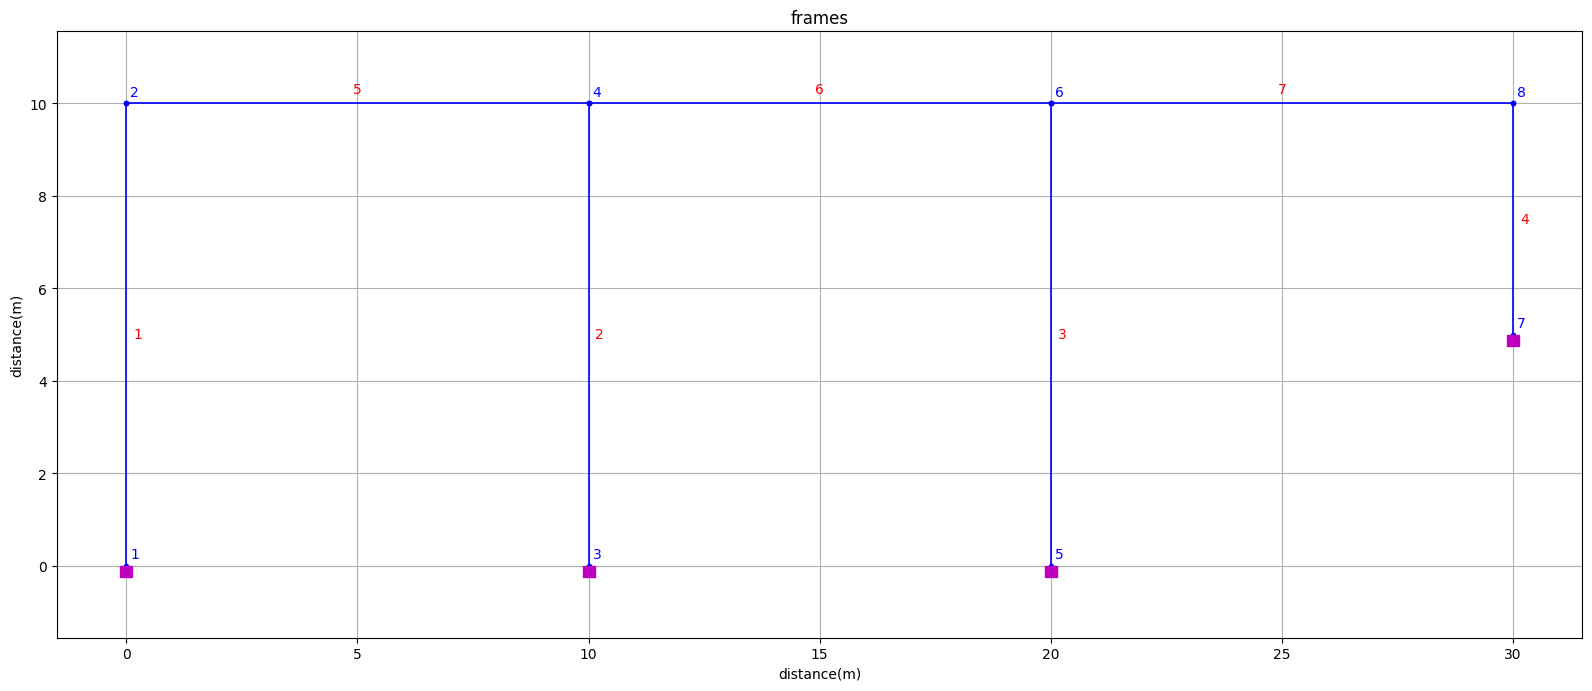

In [20]:
# Columns
for i in range(nbay+1):
    eletag = i + 1
    bottomnode = 2*eletag - 1
    topnode    = 2*eletag

    ops.element('elasticBeamColumn',eletag, bottomnode, topnode, A, E, I,1) #ops.element('elasticBeamColumn',eletag, bottomnode, topnode, A, E, I,1) 

    print(f'Column element {eletag} defined')
    ops.fix(bottomnode,1,1,1)

# Beams
for i in range(nbay):
    index = i + 1
    eletag = nbay + index + 1
    endleft  = 2*index
    endright = 2*index + 2

    ops.element('elasticBeamColumn',eletag, endleft, endright, A, E, I,1)

    print(f'Beam element {eletag} defined')



plotstructure('frames')


In [21]:
# load defination
ops.timeSeries('Linear',1)
ops.pattern('Plain',1,1)
ops.eleLoad('-ele',5,'-type','-beamUniform',-20000)
ops.eleLoad('-ele',6,'-type','-beamUniform',-30000)
ops.eleLoad('-ele',7,'-type','-beamUniform',-40000)
ops.load(2,200000,0.0,0.0)
ops.load(4,0.0,-50000,0.0)


In [22]:
# analysis
ops.system('BandGen')
ops.numberer('RCM')
ops.constraints('Transformation')
ops.integrator('LoadControl',0.1)
ops.algorithm('Linear')
ops.analysis('Static')
ops.analyze(10)



0

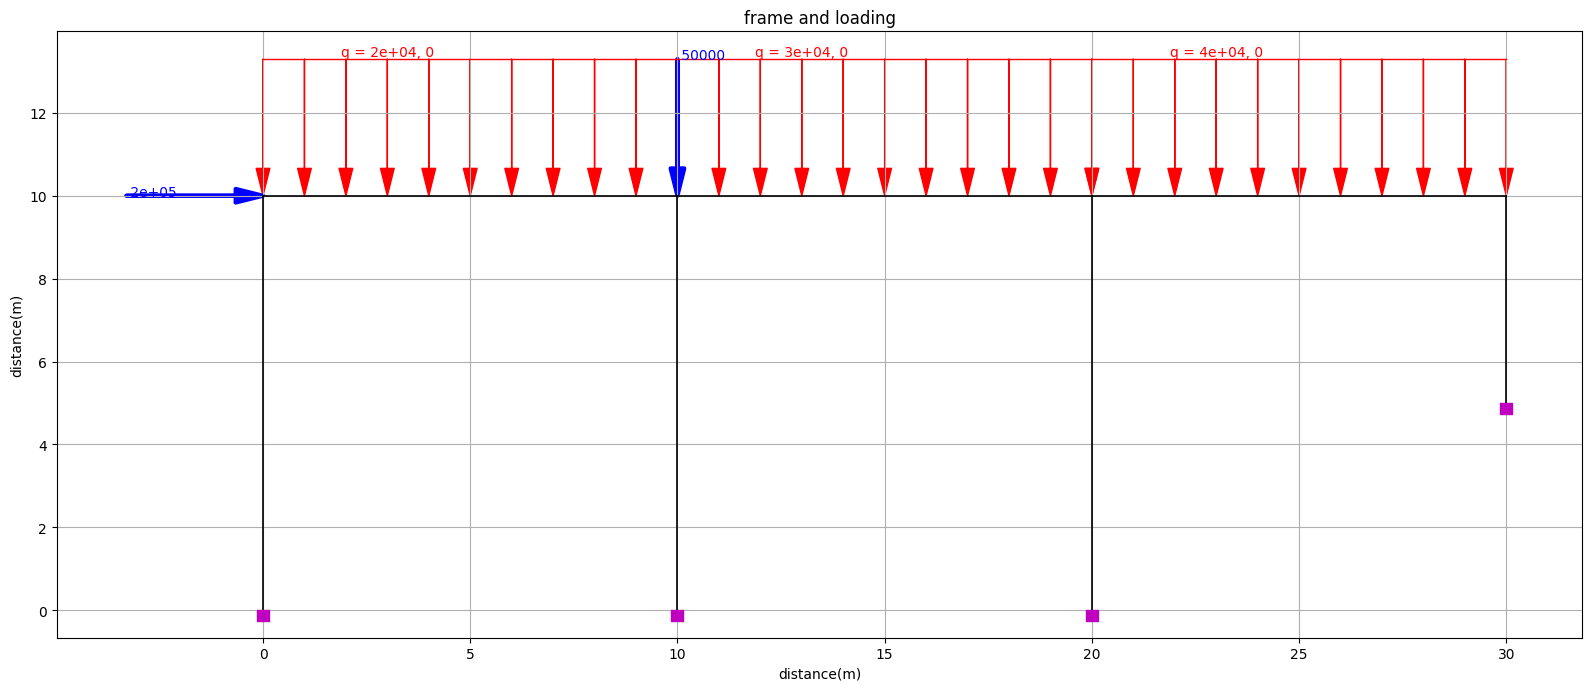

In [23]:
def plotload(title):
    opsv.plot_load(fig_wi_he=(50,20))
    plt.title(title)
    plt.xlabel('distance(m)')
    plt.ylabel('distance(m)')
    plt.grid()
    plt.show()

plotload("frame and loading")    

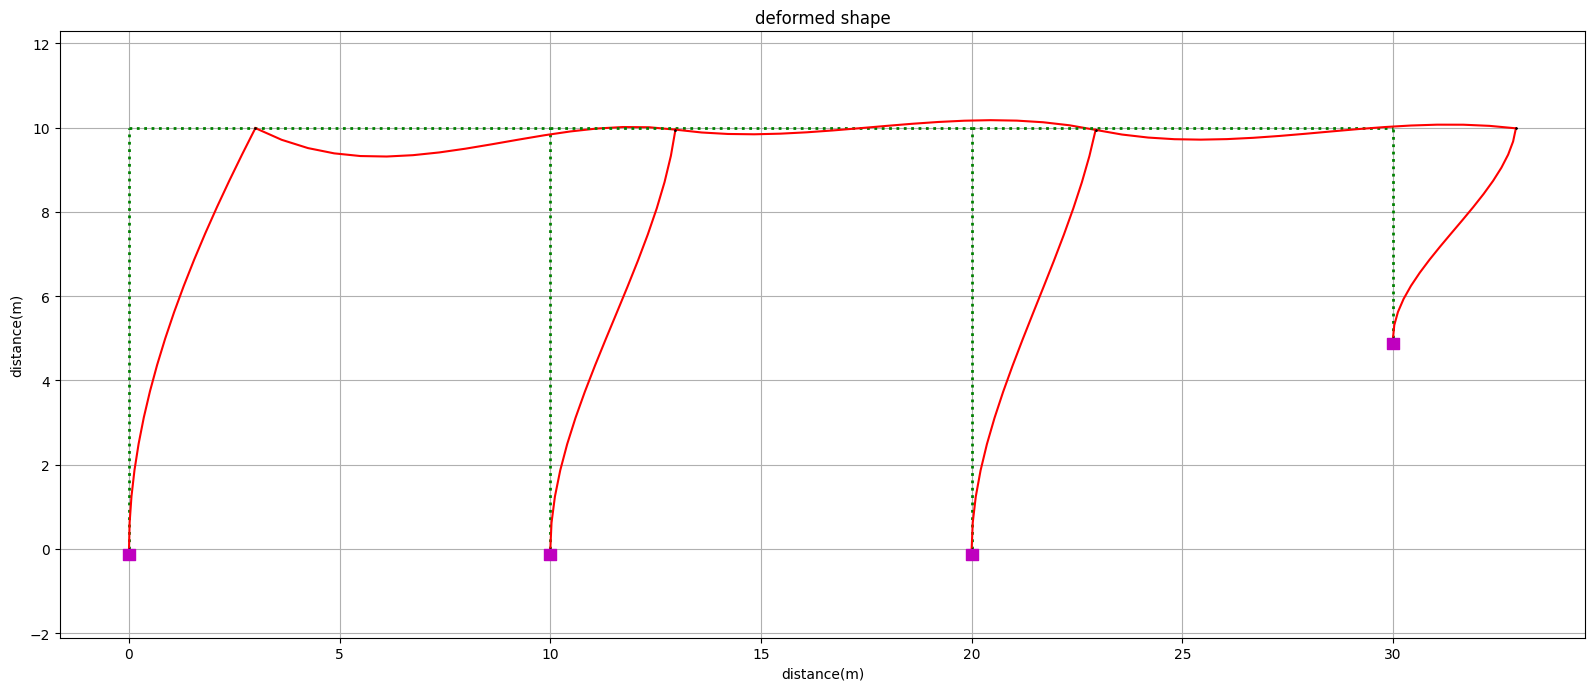

In [24]:
# deflection
s=opsv.plot_defo(fig_wi_he=(50,20),fmt_defo={'color':'red','linestyle':'solid','linewidth':1.5},
                 fmt_undefo={'color': 'green', 'linestyle': ':', 'linewidth': 2})
def shape(title):
    plt.title('deformed shape')
    plt.xlabel('distance(m)')
    plt.ylabel('distance(m)')
    plt.grid()
    plt.show()
shape('deformed shape')



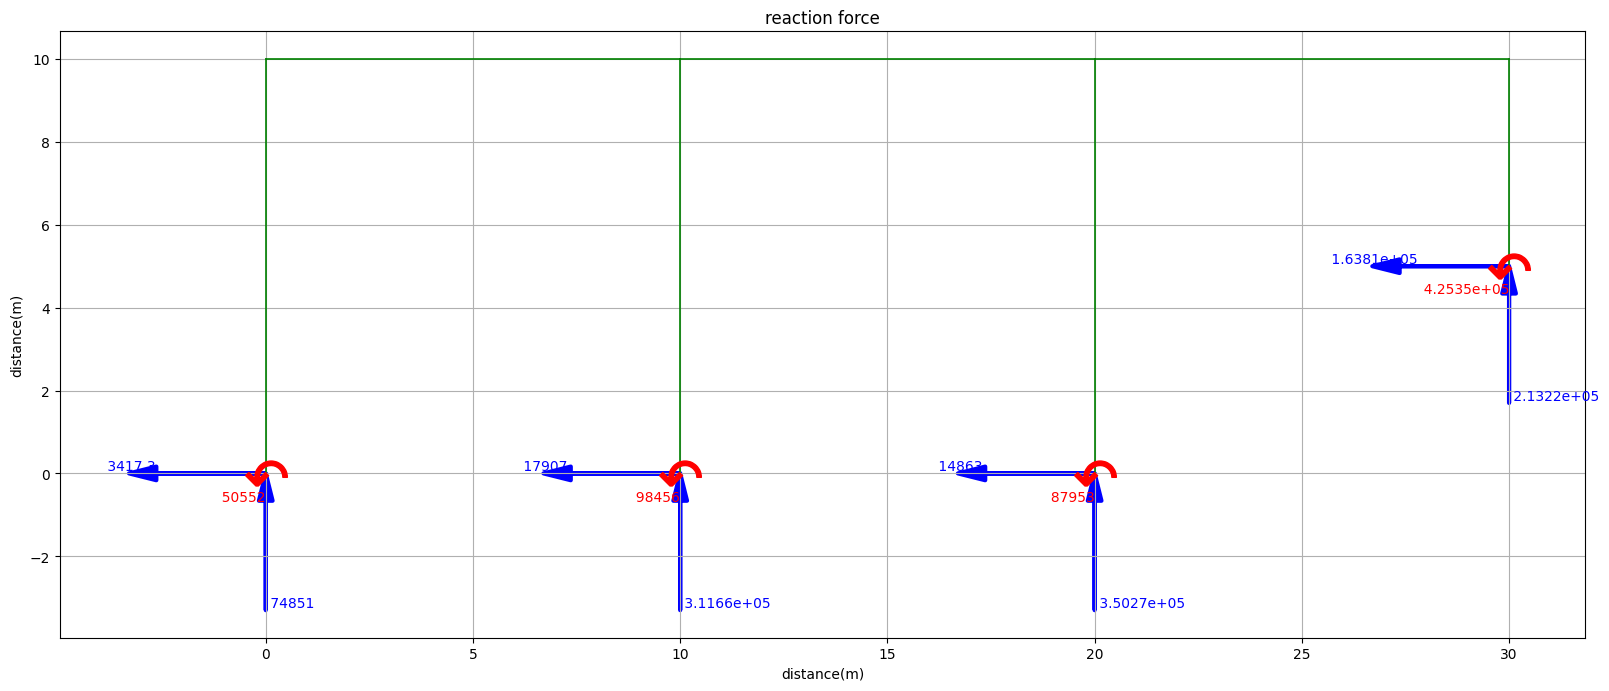

In [25]:
opsv.plot_reactions( fig_wi_he=(50,20), fig_lbrt=False, fmt_model_loads={'color': 'green', 'linestyle': 'solid', 'linewidth': 1.2, 'marker': '', 'markersize': 1})
plt.title('reaction force')
plt.xlabel('distance(m)')
plt.ylabel('distance(m)')
plt.grid()
plt.show()

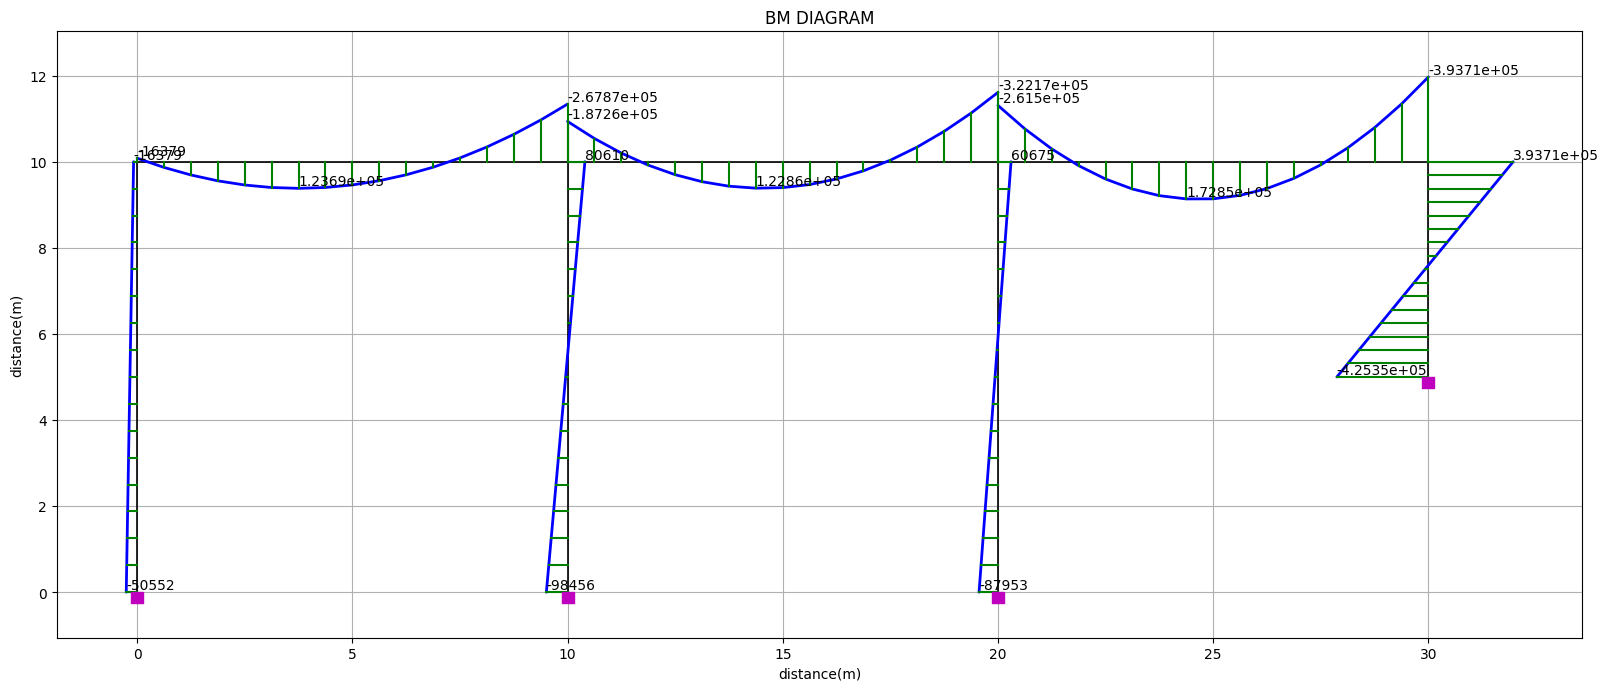

In [26]:
mfac=5.e-6
opsv.section_force_diagram_2d('M',mfac,fig_wi_he=(50,20),fmt_secforce2={'color': 'green'})
plt.title('BM DIAGRAM')
plt.xlabel('distance(m)')
plt.ylabel('distance(m)')
plt.grid()
plt.show()

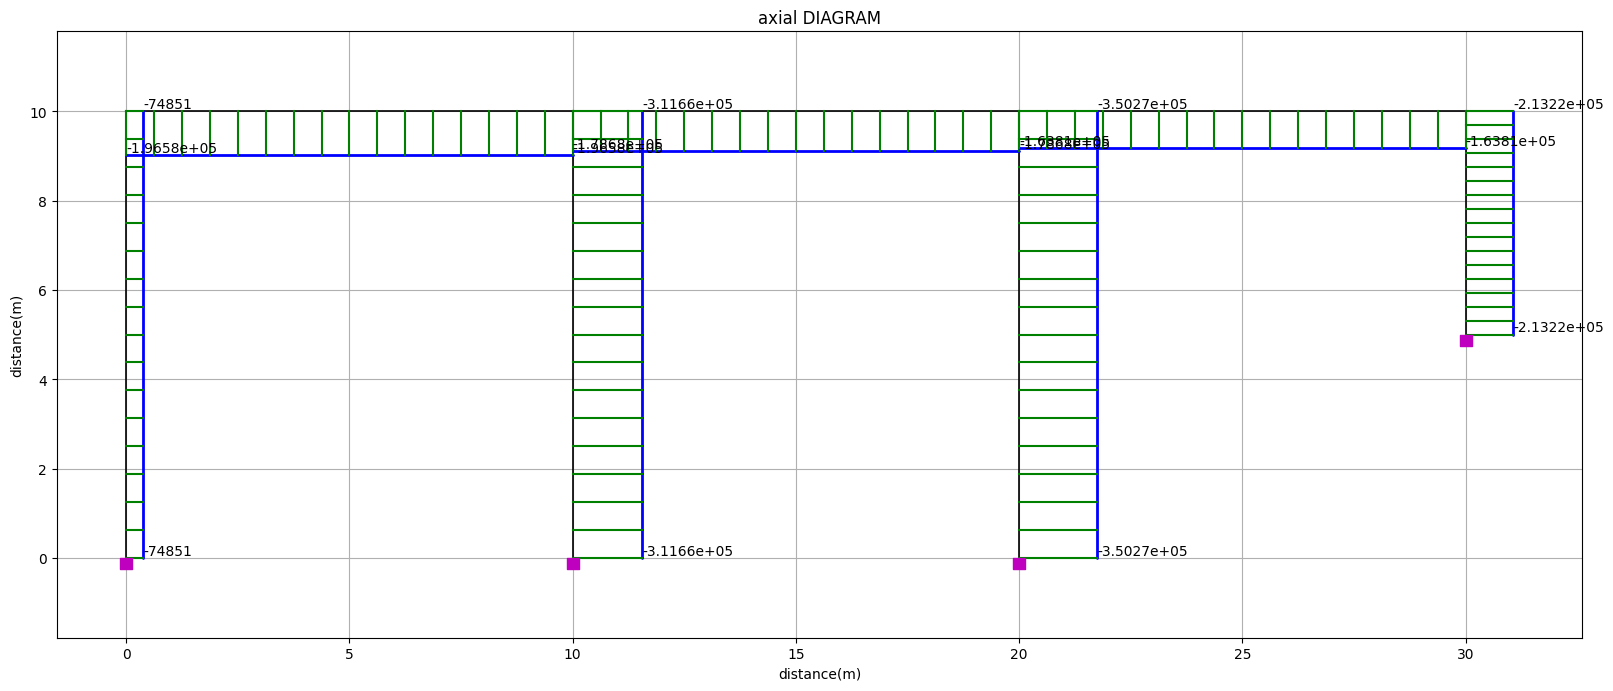

In [27]:
mfac=5.e-6
opsv.section_force_diagram_2d('N',mfac,fig_wi_he=(50,20),fmt_secforce2={'color': 'green'})
plt.title('axial DIAGRAM')
plt.xlabel('distance(m)')
plt.ylabel('distance(m)')
plt.grid()
plt.show()

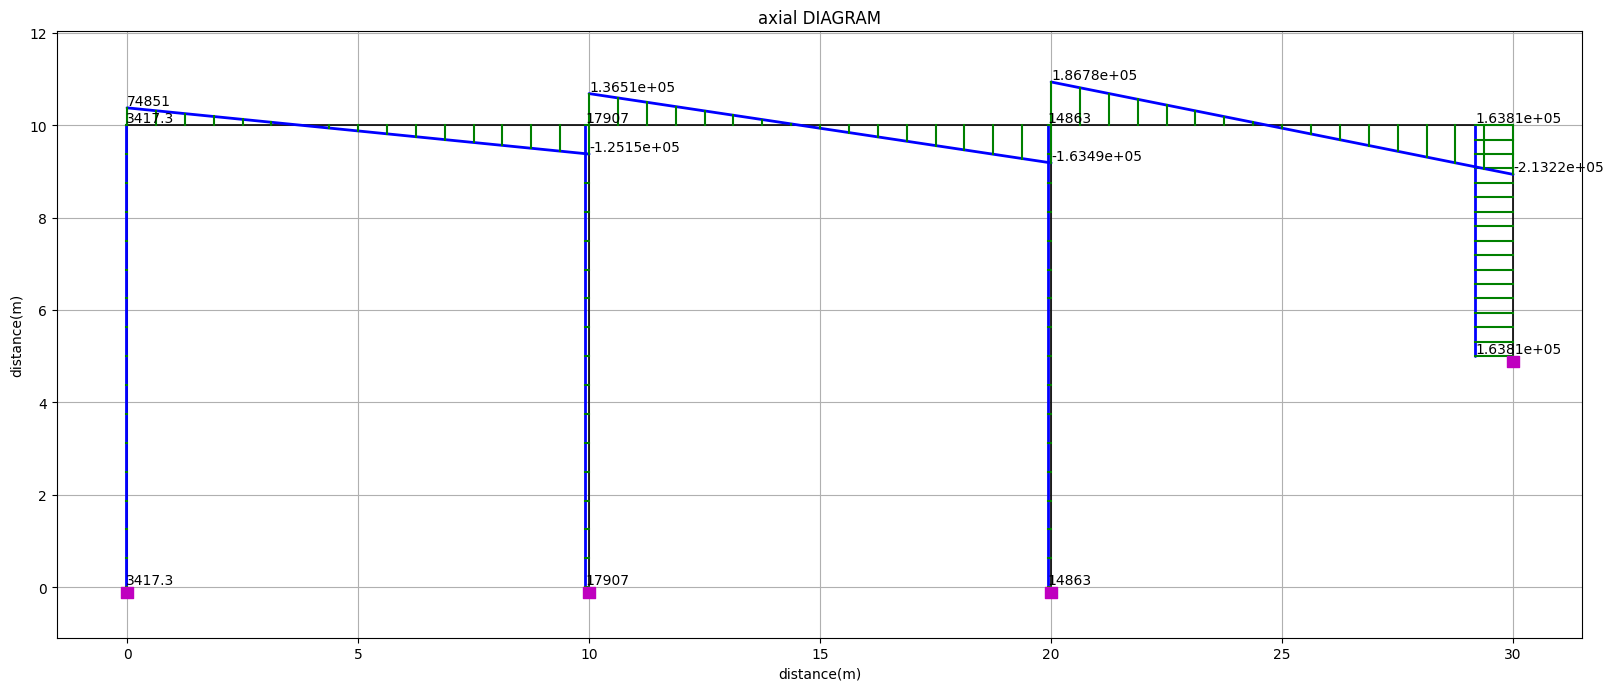

In [28]:
mfac=5.e-6
opsv.section_force_diagram_2d('V',mfac,fig_wi_he=(50,20),fmt_secforce2={'color': 'green'})
plt.title('axial DIAGRAM')
plt.xlabel('distance(m)')
plt.ylabel('distance(m)')
plt.grid()
plt.show()